### 1. Khởi tạo các thư viện cần thiết
Chúng ta sẽ import các thư viện phổ biến phục vụ cho việc xử lý dữ liệu và xây dựng mô hình.

In [97]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os


### 2. Nạp các tệp dữ liệu (Train / Val / Test) từ máy tính
Bạn có thể chạy cell dưới đây để chọn và tải lên lần lượt các file dữ liệu từ thiết bị của mình.

In [98]:
import os
import pandas as pd

# 1. Khởi tạo đường dẫn tới thư mục 'data'
DATA_DIR = os.path.join('.', 'data')

train_path = os.path.join(DATA_DIR, 'smartphones_train_clean.csv')
val_path = os.path.join(DATA_DIR, 'smartphones_val_clean.csv')
test_path = os.path.join(DATA_DIR, 'smartphones_test_clean.csv')

# 2. Nạp dữ liệu trực tiếp từ máy cục bộ (Local)

# Nạp tập TRAIN (Bắt buộc)
if os.path.exists(train_path):
    df_train = pd.read_csv(train_path)
    print(f"Đã nạp tập TRAIN: {train_path} | Kích thước: {df_train.shape}")
else:
    raise FileNotFoundError(f"LỖI: Không tìm thấy file 'train.csv' trong thư mục '{DATA_DIR}'.")

# Nạp tập VALIDATION (Tùy chọn)
if os.path.exists(val_path):
    df_val = pd.read_csv(val_path)
    print(f"Đã nạp tập VALIDATION: {val_path} | Kích thước: {df_val.shape}")
else:
    df_val = None
    print(f"Bỏ qua tập VALIDATION (Không tìm thấy file '{val_path}').")

# Nạp tập TEST (Tùy chọn)
if os.path.exists(test_path):
    df_test = pd.read_csv(test_path)
    print(f"Đã nạp tập TEST: {test_path} | Kích thước: {df_test.shape}")
else:
    df_test = None
    print(f"Bỏ qua tập TEST (Không tìm thấy file '{test_path}').")

Đã nạp tập TRAIN: .\data\smartphones_train_clean.csv | Kích thước: (1337, 21)
Đã nạp tập VALIDATION: .\data\smartphones_val_clean.csv | Kích thước: (286, 21)
Đã nạp tập TEST: .\data\smartphones_test_clean.csv | Kích thước: (287, 21)


### 3. Hiển thị thử dữ liệu của tập Train

In [99]:
pd.set_option('display.max_columns', None)
display(df_train.head())

,Hãng Sản Xuất,Giá Bán (EUR),RAM (GB),ROM (GB),Kích Thước Màn Hình (inch),Tỷ Lệ Màn Hình (%),Tấm Nền Màn Hình,Camera Sau (MP),Camera Trước (MP),Dung Lượng Pin (mAh),Thiết Kế Pin,Độ Dày (mm),Trọng Lượng (g),Cảm Biến Vân Tay,Hỗ Trợ Mạng,Hãng Chip,Số Nhân CPU (Core),Xung Nhịp CPU (GHz),Năm Ra Mắt,NFC_Clean,Độ Phân Giải Đường Chéo (Pixels)
0,QMobile,400.0,3.0,64.0,6.0,73.5,AMOLED,24.0,8.0,3500.0,Nguyên khối,9.6,210.0,Có,4G / LTE,MediaTek,8.0,2.00,2015.0,1,2937.209560
1,Panasonic,130.0,2.0,16.0,5.0,67.7,IPS LCD,13.0,5.0,2200.0,Nguyên khối,8.0,133.0,Có,4G / LTE,Snapdragon,4.0,1.25,2017.0,0,1468.604780
2,Asus,240.0,2.0,32.0,8.0,70.8,IPS LCD,5.0,1.2,2470.0,Nguyên khối,7.5,299.0,Không,4G / LTE,Intel,4.0,2.30,2014.0,1,2264.155472
3,Samsung,410.0,2.0,32.0,5.0,69.2,TFT LCD,13.0,2.0,2600.0,Tháo rời,9.1,147.0,Không,4G / LTE,Snapdragon,4.0,2.30,2013.0,1,2202.907170
4,Huawei,200.0,3.0,16.0,5.0,68.8,AMOLED,13.0,5.0,4100.0,Nguyên khối,7.9,145.0,Có,4G / LTE,MediaTek,8.0,1.40,2016.0,0,1468.604780


### 4. Quy trình Feature Engineering hoàn chỉnh (Domain, Time-Relative & Advanced Features)

Trong bước này, chúng ta gộp toàn bộ các kỹ thuật tạo đặc trưng vào một quy trình thống nhất để tránh rò rỉ dữ liệu (Data Leakage) và đảm bảo tính nhất quán giữa các tập dữ liệu Train, Validation và Test:
1. **Đặc trưng nghiệp vụ (Domain Features):** Tính chỉ số màn hình `PPI`, tỷ số thiết kế `Ty_So_Pin_Do_Day`, tổng xung nhịp, chỉ số hiệu năng và tổng camera.
2. **Đặc trưng tương đối theo thời gian (Time-Relative Features):** So sánh RAM, ROM, Camera của thiết bị với giá trị trung bình của năm ra mắt tương ứng (tính toán thống kê hoàn toàn trên tập Train).
3. **Tính toán Tuổi điện thoại:** Đo lường khoảng cách thời gian so với năm ra mắt mới nhất trong tập dữ liệu.
4. **Mã hóa nâng cao (Target Encoding & One-Hot):** Áp dụng Smoothed Target Encoding cho các biến danh mục nhiều nhóm (`Hãng Sản Xuất`, `Hãng Chip`) dựa trên tập Train, mã hóa One-Hot cho biến phân loại ít nhóm, và chuẩn hóa các biến nhị phân.

In [100]:
import pandas as pd
import numpy as np

# --- 1. ĐỊNH NGHĨA CÁC HÀM TẠO ĐẶC TRƯNG ---

def get_column_by_keyword(df, keywords, default=None):
    """Hàm bổ trợ tìm tên cột an toàn, tránh lỗi IndexError"""
    for c in df.columns:
        if any(k in c for k in keywords):
            return c
    return default

def create_domain_features(df):
    df = df.copy()

    col_screen = get_column_by_keyword(df, ['Kích Thước Màn Hình', 'Màn Hình'])
    col_diagonal_res = get_column_by_keyword(df, ['Đường Chéo (Pixels)', 'Pixels'])
    col_thickness = get_column_by_keyword(df, ['Độ Dày', 'Thickness'])
    col_battery = get_column_by_keyword(df, ['Pin', 'Battery'])
    col_cores = get_column_by_keyword(df, ['Số Nhân', 'Cores'])
    col_clock = get_column_by_keyword(df, ['Xung Nhịp', 'Clock'])
    col_cam_back = get_column_by_keyword(df, ['Camera Sau', 'Rear Camera'])
    col_cam_front = get_column_by_keyword(df, ['Camera Trước', 'Front Camera'])

    # Chỉ số PPI
    if col_diagonal_res and col_screen:
        df['PPI'] = df[col_diagonal_res] / (df[col_screen] + 1e-5)
    else:
        df['PPI'] = 0

    # Chỉ số thiết kế & hiệu năng
    if col_battery and col_thickness:
        df['Ty_So_Pin_Do_Day'] = df[col_battery] / (df[col_thickness] + 1e-5)

    if col_cores and col_clock:
        df['Tong_Xung_Nhip_CPU'] = df[col_cores] * df[col_clock]
        if 'RAM (GB)' in df.columns:
            df['Chi_So_Hieu_Nang'] = df['RAM (GB)'] * df['Tong_Xung_Nhip_CPU']

    if col_cam_back and col_cam_front:
        df['Tong_Camera_MP'] = df[col_cam_back] + df[col_cam_front]

    return df


def add_time_relative_features(df, stats, global_means_train, col_year, col_cam_back):
    df = df.copy()
    df = df.merge(stats, on=col_year, how='left')

    # Điền NaN cho năm mới ở Val/Test bằng GLOBAL MEAN thuần túy của TRAIN (Chống Data Leakage)
    df['mean_ram'] = df['mean_ram'].fillna(global_means_train['ram'])
    df['mean_rom'] = df['mean_rom'].fillna(global_means_train['rom'])
    df['mean_cam'] = df['mean_cam'].fillna(global_means_train['cam'])

    # Tính tỷ lệ so với trung bình năm
    df['RAM_So_Voi_Nam'] = df['RAM (GB)'] / (df['mean_ram'] + 1e-5)
    df['ROM_So_Voi_Nam'] = df['ROM (GB)'] / (df['mean_rom'] + 1e-5)
    df['Cam_So_Voi_Nam'] = df[col_cam_back] / (df['mean_cam'] + 1e-5)

    return df.drop(columns=['mean_ram', 'mean_rom', 'mean_cam'])


def calculate_smoothed_target_encoding(df, target, column, m=10, global_mean=0.0):
    stats = df.groupby(column)[target].agg(['count', 'sum'])
    smoothed_values = (stats['sum'] + m * global_mean) / (stats['count'] + m)
    return smoothed_values.to_dict()


# --- 2. ÁP DỤNG BIẾN ĐỔI TUẦN TỰ ---

# Bước 2.1: Tạo đặc trưng nghiệp vụ sơ bộ
df_train_feat = create_domain_features(df_train)
df_val_feat = create_domain_features(df_val)
df_test_feat = create_domain_features(df_test)

# Xác định tên các cột quan trọng
col_year = get_column_by_keyword(df_train, ['Năm', 'Year'])
col_cam_back = get_column_by_keyword(df_train, ['Camera Sau', 'Rear'])
target_col = get_column_by_keyword(df_train, ['Giá', 'Price'])

y_train = df_train[target_col]
y_val = df_val[target_col]
y_test = df_test[target_col]

# Bước 2.2: Tính toán thống kê theo thời gian CHỈ TỪ TẬP TRAIN
year_stats = df_train_feat.groupby(col_year).agg(
    mean_ram=('RAM (GB)', 'mean'),
    mean_rom=('ROM (GB)', 'mean'),
    mean_cam=(col_cam_back, 'mean')
).reset_index()

# Lưu sẵn Global Means của TRAIN
global_means_train = {
    'ram': df_train_feat['RAM (GB)'].mean(),
    'rom': df_train_feat['ROM (GB)'].mean(),
    'cam': df_train_feat[col_cam_back].mean()
}

# Áp dụng đặc trưng tương đối theo năm cho 3 tập
df_train_final = add_time_relative_features(df_train_feat, year_stats, global_means_train, col_year, col_cam_back)
df_val_final = add_time_relative_features(df_val_feat, year_stats, global_means_train, col_year, col_cam_back)
df_test_final = add_time_relative_features(df_test_feat, year_stats, global_means_train, col_year, col_cam_back)

# Bước 2.3: Tạo các đặc trưng nâng cao
max_year_train = df_train_final[col_year].max()
global_mean_target = y_train.mean()

# Tạo mapping Target Encoding từ tập TRAIN
brand_col = get_column_by_keyword(df_train_final, ['Hãng Sản Xuất', 'Brand'])
chip_col = get_column_by_keyword(df_train_final, ['Hãng Chip', 'Chip'])

brand_te_mapping = calculate_smoothed_target_encoding(df_train_final, target_col, brand_col, m=10, global_mean=global_mean_target) if brand_col else {}
chip_te_mapping = calculate_smoothed_target_encoding(df_train_final, target_col, chip_col, m=10, global_mean=global_mean_target) if chip_col else {}

def build_engineered_features(df):
    df_out = df.copy()

    # Tính tuổi thiết bị & XÓA CỘT NĂM RA MẮT GỐC để tránh đa cộng tuyến
    df_out['Tuoi_Dien_Thoai'] = max_year_train - df_out[col_year]
    df_out = df_out.drop(columns=[col_year], errors='ignore')

    # Áp dụng Target Encoding
    if brand_col and brand_col in df_out.columns:
        df_out['Hang_San_Xuat_TE'] = df_out[brand_col].map(brand_te_mapping).fillna(global_mean_target)
        df_out = df_out.drop(columns=[brand_col], errors='ignore')

    if chip_col and chip_col in df_out.columns:
        df_out['Hang_Chip_TE'] = df_out[chip_col].map(chip_te_mapping).fillna(global_mean_target)
        df_out = df_out.drop(columns=[chip_col], errors='ignore')

    # Mã hóa One-Hot các danh mục có cardinality thấp
    low_card_cols = [c for c in ['Thiết Kế Pin', 'Nhóm Màn Hình', 'Tấm Nền Màn Hình'] if c in df_out.columns]
    if low_card_cols:
        df_out = pd.get_dummies(df_out, columns=low_card_cols, drop_first=True)

    # Mã hóa nhị phân Vân Tay
    fingerprint_col = get_column_by_keyword(df_out, ['Vân Tay', 'Fingerprint'])
    if fingerprint_col and df_out[fingerprint_col].dtype == 'object':
        df_out['Cam_Bien_Van_Tay_Encoded'] = df_out[fingerprint_col].map({'Có': 1, 'Không': 0, 'yes': 1, 'no': 0}).fillna(0)
        df_out = df_out.drop(columns=[fingerprint_col])

    # Đồng bộ hóa cột NFC
    nfc_col = get_column_by_keyword(df_out, ['NFC'])
    if nfc_col:
        df_out[nfc_col] = df_out[nfc_col].astype(int)

    # Mã hóa One-Hot cho các cột phân loại còn sót lại
    remaining_cat_cols = df_out.select_dtypes(include=['object', 'category']).columns.tolist()
    if remaining_cat_cols:
        df_out = pd.get_dummies(df_out, columns=remaining_cat_cols, drop_first=True)

    return df_out

# Áp dụng hàm biến đổi cho cả 3 tập
df_train_eng = build_engineered_features(df_train_final)
df_val_eng = build_engineered_features(df_val_final)
df_test_eng = build_engineered_features(df_test_final)

# Chia tách X, y
X_train_eng = df_train_eng.drop(columns=[target_col], errors='ignore')
y_train_eng = df_train_eng[target_col]

X_val_eng = df_val_eng.drop(columns=[target_col], errors='ignore')
y_val_eng = df_val_eng[target_col]

X_test_eng = df_test_eng.drop(columns=[target_col], errors='ignore')
y_test_eng = df_test_eng[target_col]

# Căn chỉnh đồng bộ chính xác danh sách và thứ tự cột theo X_train_eng bằng reindex
X_train_eng = X_train_eng.astype(float)
X_val_eng = X_val_eng.reindex(columns=X_train_eng.columns, fill_value=0).astype(float)
X_test_eng = X_test_eng.reindex(columns=X_train_eng.columns, fill_value=0).astype(float)

print("Đã hoàn thành gộp và xử lý Feature Engineering thống nhất!")
print(f"Kích thước tập Train: {X_train_eng.shape}")
print(f"Kích thước tập Val:   {X_val_eng.shape}")
print(f"Kích thước tập Test:  {X_test_eng.shape}")

Đã hoàn thành gộp và xử lý Feature Engineering thống nhất!
Kích thước tập Train: (1337, 34)
Kích thước tập Val:   (286, 34)
Kích thước tập Test:  (287, 34)


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_16896\990341350.py:148: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  remaining_cat_cols = df_out.select_dtypes(include=['object', 'category']).columns.tolist()
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_16896\990341350.py:148: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pa

In [101]:
display(X_train_eng.head())

,RAM (GB),ROM (GB),Kích Thước Màn Hình (inch),Tỷ Lệ Màn Hình (%),Camera Sau (MP),Camera Trước (MP),Dung Lượng Pin (mAh),Độ Dày (mm),Trọng Lượng (g),Số Nhân CPU (Core),Xung Nhịp CPU (GHz),NFC_Clean,Độ Phân Giải Đường Chéo (Pixels),PPI,Ty_So_Pin_Do_Day,Tong_Xung_Nhip_CPU,Chi_So_Hieu_Nang,Tong_Camera_MP,RAM_So_Voi_Nam,ROM_So_Voi_Nam,Cam_So_Voi_Nam,Tuoi_Dien_Thoai,Hang_San_Xuat_TE,Hang_Chip_TE,Thiết Kế Pin_Tháo rời,Tấm Nền Màn Hình_IPS LCD,Tấm Nền Màn Hình_OLED,Tấm Nền Màn Hình_PLS LCD,Tấm Nền Màn Hình_Super AMOLED,Tấm Nền Màn Hình_Super LCD,Tấm Nền Màn Hình_TFT LCD,Cảm Biến Vân Tay_Không,Hỗ Trợ Mạng_3G,Hỗ Trợ Mạng_4G / LTE
0,3.0,64.0,6.0,73.5,24.0,8.0,3500.0,9.6,210.0,8.0,2.00,1.0,2937.209560,489.534111,364.582954,16.0,48.0,32.0,1.612013,2.970420,2.182691,2.0,177.026926,189.263601,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,2.0,16.0,5.0,67.7,13.0,5.0,2200.0,8.0,133.0,4.0,1.25,0.0,1468.604780,293.720369,274.999656,5.0,10.0,18.0,0.633389,0.375510,1.007581,0.0,193.225131,246.753508,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,2.0,32.0,8.0,70.8,5.0,1.2,2470.0,7.5,299.0,4.0,2.30,1.0,2264.155472,283.019080,329.332894,9.2,18.4,6.2,1.368182,2.143343,0.526916,3.0,275.871462,213.455497,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
3,2.0,32.0,5.0,69.2,13.0,2.0,2600.0,9.1,147.0,4.0,2.30,1.0,2202.907170,440.580553,285.713972,9.2,18.4,15.0,1.443928,2.121901,1.565406,4.0,277.710522,246.753508,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0
4,3.0,16.0,5.0,68.8,13.0,5.0,4100.0,7.9,145.0,8.0,1.40,0.0,1468.604780,293.720369,518.986685,11.2,33.6,18.0,1.123539,0.435411,1.062826,1.0,256.032277,189.263601,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


### 5. Huẩn luyện Random Forest và XG Boost trên tập dữ liệu đã xử lý, lấy baseline trước khi tiến hành tinh chỉnh tham số

In [102]:
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

def evaluate_model(y_true, y_pred, model_name="Model"):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"--- {model_name} ---")
    print(f"MAE : {mae:.2f} EUR")
    print(f"RMSE: {rmse:.2f} EUR")
    print(f"R2  : {r2:.4f}\n")

# 1. Random Forest Baseline
rf_baseline = RandomForestRegressor(random_state=42)
rf_baseline.fit(X_train_eng, y_train_eng)

print("=== EVALUATION ON VALIDATION SET ===")
evaluate_model(y_val_eng, rf_baseline.predict(X_val_eng), "Random Forest (Baseline)")

# 2. XGBoost Baseline
xgb_baseline = XGBRegressor(random_state=42, n_estimators=100, learning_rate=0.1)
xgb_baseline.fit(X_train_eng, y_train_eng)

evaluate_model(y_val_eng, xgb_baseline.predict(X_val_eng), "XGBoost (Baseline)")

=== EVALUATION ON VALIDATION SET ===
--- Random Forest (Baseline) ---
MAE : 50.62 EUR
RMSE: 73.46 EUR
R2  : 0.7208

--- XGBoost (Baseline) ---
MAE : 48.26 EUR
RMSE: 66.90 EUR
R2  : 0.7685



In [103]:
import pandas as pd
import matplotlib.pyplot as plt

# Lấy độ quan trọng đặc trưng từ Random Forest / XGBoost
importances = pd.Series(xgb_baseline.feature_importances_, index=X_train_eng.columns)
top_features = importances.sort_values(ascending=False).head(15)

print("Top 15 đặc trưng quan trọng nhất:")
print(top_features)

Top 15 đặc trưng quan trọng nhất:
Độ Phân Giải Đường Chéo (Pixels)    0.365615
Xung Nhịp CPU (GHz)                 0.158810
ROM (GB)                            0.081832
Cam_So_Voi_Nam                      0.051153
NFC_Clean                           0.043360
Cảm Biến Vân Tay_Không              0.040849
RAM_So_Voi_Nam                      0.028175
PPI                                 0.021832
Hang_San_Xuat_TE                    0.019716
Chi_So_Hieu_Nang                    0.015309
ROM_So_Voi_Nam                      0.013960
Tong_Xung_Nhip_CPU                  0.013442
Tấm Nền Màn Hình_IPS LCD            0.011461
Tong_Camera_MP                      0.011178
Tấm Nền Màn Hình_Super AMOLED       0.010853
dtype: float32


### 6. Lọc đặc trưng dựa trên Feature Importance và Đánh giá lại mô hình

Chúng ta tiến hành lọc các đặc trưng đóng góp ít hơn 0.5% vào mô hình XGBoost, sau đó huấn luyện và đánh giá lại cả hai mô hình **Random Forest** và **XGBoost** trên bộ dữ liệu tinh gọn này.

In [104]:
# 1. Chọn ngưỡng lọc (ví dụ: lấy các biến đóng góp > 0.5% vào mô hình)
threshold = 0.005
selected_features = importances[importances > threshold].index.tolist()

print(f"Số lượng biến ban đầu: {X_train_eng.shape[1]}")
print(f"Số lượng biến giữ lại sau khi lọc: {len(selected_features)}")
print("Các biến được giữ lại:", selected_features)

# 2. Tạo tập dữ liệu mới chỉ chứa các đặc trưng quan trọng
X_train_sub = X_train_eng[selected_features]
X_val_sub = X_val_eng[selected_features]
X_test_sub = X_test_eng[selected_features]

Số lượng biến ban đầu: 34
Số lượng biến giữ lại sau khi lọc: 28
Các biến được giữ lại: ['ROM (GB)', 'Tỷ Lệ Màn Hình (%)', 'Camera Sau (MP)', 'Camera Trước (MP)', 'Dung Lượng Pin (mAh)', 'Độ Dày (mm)', 'Trọng Lượng (g)', 'Số Nhân CPU (Core)', 'Xung Nhịp CPU (GHz)', 'NFC_Clean', 'Độ Phân Giải Đường Chéo (Pixels)', 'PPI', 'Ty_So_Pin_Do_Day', 'Tong_Xung_Nhip_CPU', 'Chi_So_Hieu_Nang', 'Tong_Camera_MP', 'RAM_So_Voi_Nam', 'ROM_So_Voi_Nam', 'Cam_So_Voi_Nam', 'Tuoi_Dien_Thoai', 'Hang_San_Xuat_TE', 'Hang_Chip_TE', 'Thiết Kế Pin_Tháo rời', 'Tấm Nền Màn Hình_IPS LCD', 'Tấm Nền Màn Hình_Super AMOLED', 'Tấm Nền Màn Hình_Super LCD', 'Cảm Biến Vân Tay_Không', 'Hỗ Trợ Mạng_3G']


In [105]:
# 3. Huấn luyện lại Random Forest trên tập dữ liệu đã lọc
rf_sub = RandomForestRegressor(random_state=42)
rf_sub.fit(X_train_sub, y_train_eng)

# 4. Huấn luyện lại XGBoost trên tập dữ liệu đã lọc
xgb_sub = XGBRegressor(random_state=42, n_estimators=100, learning_rate=0.1)
xgb_sub.fit(X_train_sub, y_train_eng)

# 5. Đánh giá và so sánh trực tiếp kết quả
print("=== KẾT QUẢ ĐÁNH GIÁ SAU KHI LỌC ĐẶC TRƯNG (TRÊN TẬP VALIDATION) ===\n")
evaluate_model(y_val_eng, rf_sub.predict(X_val_sub), "Random Forest (Sau khi lọc)")
evaluate_model(y_val_eng, xgb_sub.predict(X_val_sub), "XGBoost (Sau khi lọc)")

=== KẾT QUẢ ĐÁNH GIÁ SAU KHI LỌC ĐẶC TRƯNG (TRÊN TẬP VALIDATION) ===

--- Random Forest (Sau khi lọc) ---
MAE : 50.31 EUR
RMSE: 72.67 EUR
R2  : 0.7268

--- XGBoost (Sau khi lọc) ---
MAE : 48.57 EUR
RMSE: 67.57 EUR
R2  : 0.7639



### 7. Xác nhận cấu hình dữ liệu huấn luyện chính thức

Vì việc lọc bỏ đặc trưng theo ngưỡng không mang lại cải tiến hiệu năng trên tập Validation, chúng ta thống nhất **giữ lại toàn bộ 34 đặc trưng** đã được tạo từ bước Feature Engineering phục vụ cho quá trình tinh chỉnh mô hình phía sau.

* Bộ dữ liệu chính thức: `X_train_eng`, `X_val_eng`, `X_test_eng`

In [106]:
# Xác nhận lại các biến dữ liệu sử dụng từ thời điểm này
X_train_final = X_train_eng
X_val_final = X_val_eng
X_test_final = X_test_eng

print("Xác nhận sử dụng bộ dữ liệu đầy đủ đặc trưng:")
print(f"- Train: {X_train_final.shape}")
print(f"- Val:   {X_val_final.shape}")
print(f"- Test:  {X_test_final.shape}")

Xác nhận sử dụng bộ dữ liệu đầy đủ đặc trưng:
- Train: (1337, 34)
- Val:   (286, 34)
- Test:  (287, 34)


In [107]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Dải tham số đơn giản cho Random Forest
param_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [6, 10, 15],
    'min_samples_split': [2, 5, 10]
}

# 2. Tìm kiếm tham số trên bộ dữ liệu đầy đủ (final)
rf_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_distributions=param_rf,
    n_iter=10,
    scoring='neg_mean_absolute_error',
    cv=5,
    random_state=42,
    n_jobs=-1
)

rf_search.fit(X_train_final, y_train_eng)
best_rf = rf_search.best_estimator_

print("=== THAM SỐ RANDOM FOREST TỐI ƯU ===")
print(rf_search.best_params_)

# 3. Định nghĩa hàm in chỉ số đánh giá (Metrics)
def print_evaluation_metrics(y_true, y_pred, set_name="Dataset"):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"\n--- Đánh giá trên {set_name} ---")
    print(f"  MAE  (Sai số tuyệt đối trung bình) : {mae:.2f} EUR")
    print(f"  RMSE (Căn lỗi bình phương trung bình): {rmse:.2f} EUR")
    print(f"  R2   (Hệ số xác định)             : {r2:.4f}")

# 4. In kết quả đánh giá cho các tập dữ liệu đầy đủ đặc trưng
print("\n=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH RANDOM FOREST ===")
print_evaluation_metrics(y_train_eng, best_rf.predict(X_train_final), "Tập TRAIN")

if 'X_val_final' in locals() and 'y_val_eng' in locals():
    print_evaluation_metrics(y_val_eng, best_rf.predict(X_val_final), "Tập VALIDATION")

if 'X_test_final' in locals() and 'y_test_eng' in locals():
    print_evaluation_metrics(y_test_eng, best_rf.predict(X_test_final), "Tập TEST")

=== THAM SỐ RANDOM FOREST TỐI ƯU ===
{'n_estimators': 100, 'min_samples_split': 5, 'max_depth': 15}

=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH RANDOM FOREST ===

--- Đánh giá trên Tập TRAIN ---
  MAE  (Sai số tuyệt đối trung bình) : 22.47 EUR
  RMSE (Căn lỗi bình phương trung bình): 34.96 EUR
  R2   (Hệ số xác định)             : 0.9348

--- Đánh giá trên Tập VALIDATION ---
  MAE  (Sai số tuyệt đối trung bình) : 50.42 EUR
  RMSE (Căn lỗi bình phương trung bình): 72.86 EUR
  R2   (Hệ số xác định)             : 0.7254

--- Đánh giá trên Tập TEST ---
  MAE  (Sai số tuyệt đối trung bình) : 48.40 EUR
  RMSE (Căn lỗi bình phương trung bình): 69.42 EUR
  R2   (Hệ số xác định)             : 0.7273


In [108]:
import numpy as np
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Dải tham số đơn giản cho XGBoost
param_xgb = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.03, 0.05, 0.1],
    'max_depth': [3, 4, 5, 6],
    'subsample': [0.7, 0.8, 0.9]
}

# 2. Tìm kiếm tham số trên bộ dữ liệu đầy đủ (final)
xgb_search = RandomizedSearchCV(
    estimator=XGBRegressor(random_state=42, n_jobs=-1),
    param_distributions=param_xgb,
    n_iter=10,
    scoring='neg_mean_absolute_error',
    cv=5,
    random_state=42,
    n_jobs=-1
)

xgb_search.fit(X_train_final, y_train_eng)
best_xgb = xgb_search.best_estimator_

print("=== THAM SỐ XGBOOST TỐI ƯU ===")
print(xgb_search.best_params_)

# 4. In kết quả đánh giá cho các tập dữ liệu đầy đủ đặc trưng
print("\n=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH XGBOOST ===")
print_evaluation_metrics(y_train_eng, best_xgb.predict(X_train_final), "Tập TRAIN")

if 'X_val_final' in locals() and 'y_val_eng' in locals():
    print_evaluation_metrics(y_val_eng, best_xgb.predict(X_val_final), "Tập VALIDATION")

if 'X_test_final' in locals() and 'y_test_eng' in locals():
    print_evaluation_metrics(y_test_eng, best_xgb.predict(X_test_final), "Tập TEST")

=== THAM SỐ XGBOOST TỐI ƯU ===
{'subsample': 0.9, 'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.05}

=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH XGBOOST ===

--- Đánh giá trên Tập TRAIN ---
  MAE  (Sai số tuyệt đối trung bình) : 18.69 EUR
  RMSE (Căn lỗi bình phương trung bình): 25.10 EUR
  R2   (Hệ số xác định)             : 0.9664

--- Đánh giá trên Tập VALIDATION ---
  MAE  (Sai số tuyệt đối trung bình) : 46.19 EUR
  RMSE (Căn lỗi bình phương trung bình): 64.78 EUR
  R2   (Hệ số xác định)             : 0.7829

--- Đánh giá trên Tập TEST ---
  MAE  (Sai số tuyệt đối trung bình) : 46.45 EUR
  RMSE (Căn lỗi bình phương trung bình): 66.81 EUR
  R2   (Hệ số xác định)             : 0.7474


In [109]:
# Dự đoán kết hợp trọng số trên tập Test sử dụng đúng tập đặc trưng đầy đủ X_test_final
y_pred_rf = best_rf.predict(X_test_final)
y_pred_xgb = best_xgb.predict(X_test_final)

# Gộp dự đoán: 70% XGBoost + 30% Random Forest
y_pred_ensemble = 0.7 * y_pred_xgb + 0.3 * y_pred_rf

print("=== KẾT QUẢ MÔ HÌNH ENSEMBLE (BLENDING) ===")
print_evaluation_metrics(y_test_eng, y_pred_ensemble, "Tập TEST (Ensemble)")

=== KẾT QUẢ MÔ HÌNH ENSEMBLE (BLENDING) ===

--- Đánh giá trên Tập TEST (Ensemble) ---
  MAE  (Sai số tuyệt đối trung bình) : 46.52 EUR
  RMSE (Căn lỗi bình phương trung bình): 66.82 EUR
  R2   (Hệ số xác định)             : 0.7473


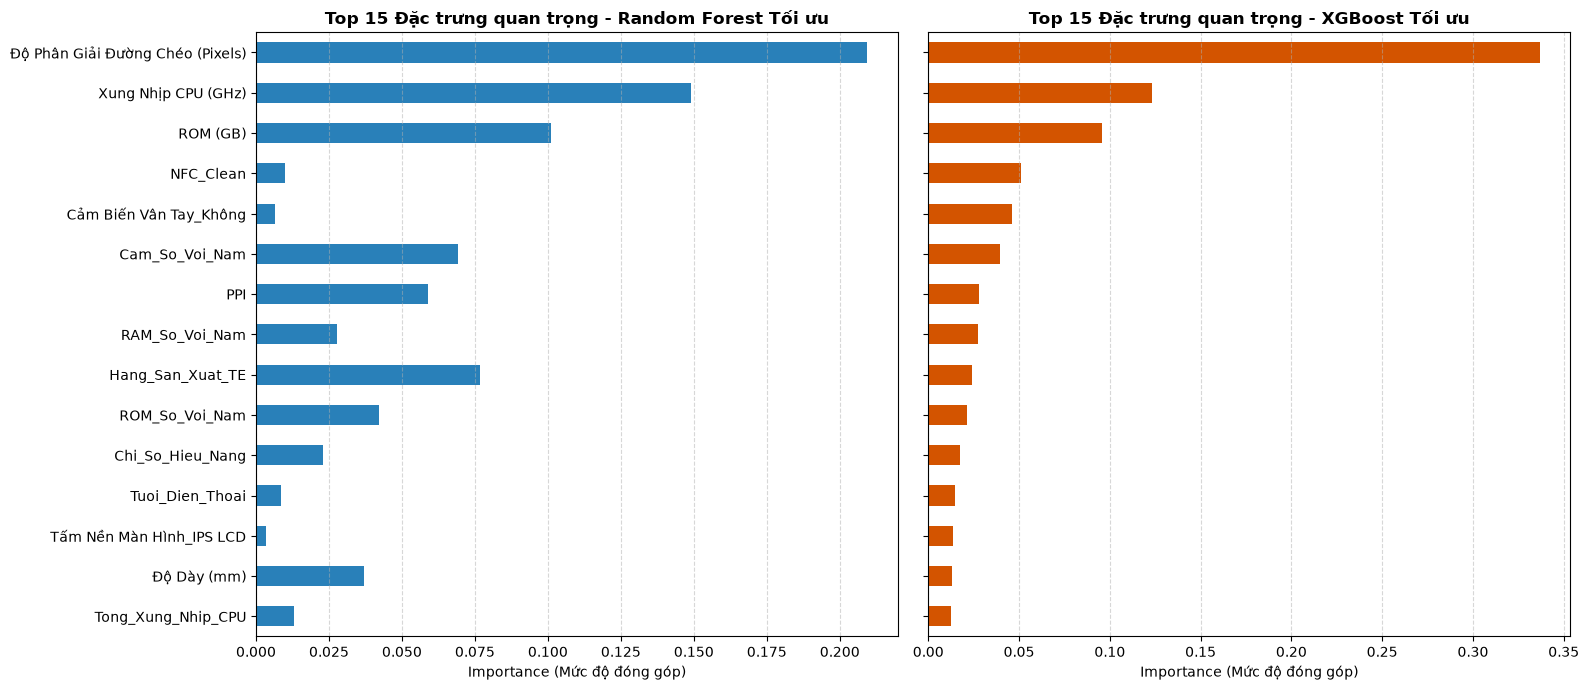

=== TOP 10 ĐẶC TRƯNG QUAN TRỌNG NHẤT (XGBOOST TỐI ƯU) ===


,Đặc trưng,Random Forest,XGBoost
0,Độ Phân Giải Đường Chéo (Pixels),0.209392,0.336658
1,Xung Nhịp CPU (GHz),0.148951,0.122997
2,ROM (GB),0.101196,0.095799
3,NFC_Clean,0.010010,0.050925
4,Cảm Biến Vân Tay_Không,0.006410,0.045910
5,Cam_So_Voi_Nam,0.069374,0.039632
6,PPI,0.058934,0.027762
7,RAM_So_Voi_Nam,0.027711,0.027373
8,Hang_San_Xuat_TE,0.076845,0.023845
9,ROM_So_Voi_Nam,0.042030,0.021363


In [111]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Tự động lấy danh sách cột thực tế mà mô hình đã học (tránh hoàn toàn lỗi lệch số lượng cột)
feature_cols = getattr(
    best_rf,
    'feature_names_in_',
    X_train_final.columns if 'X_train_final' in locals() else X_train_eng.columns,
)

# 2. Trích xuất Feature Importance từ 2 mô hình đã Tuning
rf_final_imp = pd.Series(best_rf.feature_importances_, index=feature_cols)
xgb_final_imp = pd.Series(best_xgb.feature_importances_, index=feature_cols)

df_final_imp = pd.DataFrame(
    {'Random Forest': rf_final_imp, 'XGBoost': xgb_final_imp}
)

# 3. Lấy Top 15 đặc trưng quan trọng nhất (theo mức đóng góp của XGBoost) để biểu đồ hiển thị rõ ràng
top_15 = df_final_imp.sort_values(by='XGBoost', ascending=True).tail(15)

# 4. Vẽ biểu đồ so sánh trực quan
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)

top_15['Random Forest'].plot(kind='barh', ax=axes[0], color='#2980b9')
axes[0].set_title(
    'Top 15 Đặc trưng quan trọng - Random Forest Tối ưu',
    fontsize=12,
    fontweight='bold',
)
axes[0].set_xlabel('Importance (Mức độ đóng góp)')
axes[0].grid(axis='x', linestyle='--', alpha=0.5)

top_15['XGBoost'].plot(kind='barh', ax=axes[1], color='#d35400')
axes[1].set_title(
    'Top 15 Đặc trưng quan trọng - XGBoost Tối ưu',
    fontsize=12,
    fontweight='bold',
)
axes[1].set_xlabel('Importance (Mức độ đóng góp)')
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# In ra bảng số liệu Top 10 đặc trưng hàng đầu
print('=== TOP 10 ĐẶC TRƯNG QUAN TRỌNG NHẤT (XGBOOST TỐI ƯU) ===')
display(
    df_final_imp.sort_values(by='XGBoost', ascending=False)
    .head(10)
    .reset_index()
    .rename(columns={'index': 'Đặc trưng'})
)